# IBD - Laboratorio 10  
## Filtrado colaborativo con Spark ALS en Google Colab

En este laboratorio construiremos un sistema de recomendación utilizando el conjunto de datos **MovieLens 100K** y el algoritmo **Alternating Least Squares (ALS)** disponible en Spark MLlib.

El notebook está preparado para ejecutarse directamente en **Google Colab**.


## 1. Configuración para Google Colab

Ejecuta primero la siguiente celda. Instala Java y PySpark, y después configura el entorno necesario para Spark.


In [1]:
# Install Java and PySpark for Google Colab
!apt-get update -qq
!apt-get install -y openjdk-17-jdk-headless -qq > /dev/null
!pip install -q pyspark

import os
os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"

print("Java y PySpark están listos.")


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)
Java y PySpark están listos.


## 2. Importar librerías e iniciar Spark


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import pyspark
from pyspark.sql import SparkSession
from pyspark.sql.types import StructType, StructField, IntegerType, StringType
from pyspark.sql.functions import col, explode, round as spark_round, count, avg, desc

spark = (
    SparkSession.builder
    .appName("IBD_Lab10_Collaborative_Filtering")
    .master("local[*]")
    .config("spark.ui.port", "4050")
    .getOrCreate()
)

spark


## 3. Descargar el conjunto de datos MovieLens 100K, https://grouplens.org/datasets/movielens/100k/

Usamos el conjunto de datos oficial MovieLens 100K de GroupLens.  
El archivo se descarga directamente, por lo que no se requiere autenticación con Google Drive.


In [3]:
import urllib.request
import zipfile
from pathlib import Path

data_dir = Path("/content/movielens")
zip_path = data_dir / "ml-100k.zip"
extract_dir = data_dir / "ml-100k"

data_dir.mkdir(parents=True, exist_ok=True)

url = "https://files.grouplens.org/datasets/movielens/ml-100k.zip"

if not extract_dir.exists():
    print("Descargando el conjunto de datos MovieLens 100K...")
    urllib.request.urlretrieve(url, zip_path)

    print("Extrayendo el conjunto de datos...")
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(data_dir)
else:
    print("El conjunto de datos ya está descargado.")

print("Carpeta del conjunto de datos:", extract_dir)


Descargando el conjunto de datos MovieLens 100K...
Extrayendo el conjunto de datos...
Carpeta del conjunto de datos: /content/movielens/ml-100k


## 4. Cargar las valoraciones y la información de las películas

El archivo de valoraciones contiene:

- `user_id`
- `item_id`
- `rating`
- `timestamp`

El archivo de ítems contiene el título de la película para cada `item_id`.


In [4]:
schema_ratings = StructType([
    StructField("user_id", IntegerType(), False),
    StructField("item_id", IntegerType(), False),
    StructField("rating", IntegerType(), False),
    StructField("timestamp", IntegerType(), False)
])

ratings = (
    spark.read
    .option("sep", "\t")
    .csv(str(extract_dir / "u.data"), header=False, schema=schema_ratings)
)

items_raw = (
    spark.read
    .option("sep", "|")
    .option("encoding", "ISO-8859-1")
    .csv(str(extract_dir / "u.item"), header=False)
)

items = (
    items_raw
    .select(
        col("_c0").cast("int").alias("item_id"),
        col("_c1").alias("movie")
    )
)

ratings.cache()
items.cache()

print("Ratings schema:")
ratings.printSchema()

print("Items schema:")
items.printSchema()


Ratings schema:
root
 |-- user_id: integer (nullable = true)
 |-- item_id: integer (nullable = true)
 |-- rating: integer (nullable = true)
 |-- timestamp: integer (nullable = true)

Items schema:
root
 |-- item_id: integer (nullable = true)
 |-- movie: string (nullable = true)



## 5. Explorar los datos


In [5]:
print("Número de valoraciones:", ratings.count())
print("Número de usuarios:", ratings.select("user_id").distinct().count())
print("Número de películas:", items.count())

ratings.show(5)
items.show(5, truncate=False)


Número de valoraciones: 100000
Número de usuarios: 943
Número de películas: 1682
+-------+-------+------+---------+
|user_id|item_id|rating|timestamp|
+-------+-------+------+---------+
|    196|    242|     3|881250949|
|    186|    302|     3|891717742|
|     22|    377|     1|878887116|
|    244|     51|     2|880606923|
|    166|    346|     1|886397596|
+-------+-------+------+---------+
only showing top 5 rows
+-------+-----------------+
|item_id|movie            |
+-------+-----------------+
|1      |Toy Story (1995) |
|2      |GoldenEye (1995) |
|3      |Four Rooms (1995)|
|4      |Get Shorty (1995)|
|5      |Copycat (1995)   |
+-------+-----------------+
only showing top 5 rows


In [6]:
import datetime

timestamp_value = 881250949
datetime_object = datetime.datetime.fromtimestamp(timestamp_value)

print(f"Unix timestamp: {timestamp_value}")
print(f"Converted date and time: {datetime_object}")

Unix timestamp: 881250949
Converted date and time: 1997-12-04 15:55:49


### Distribución de las valoraciones


+------+-----+
|rating|count|
+------+-----+
|     1| 6110|
|     2|11370|
|     3|27145|
|     4|34174|
|     5|21201|
+------+-----+



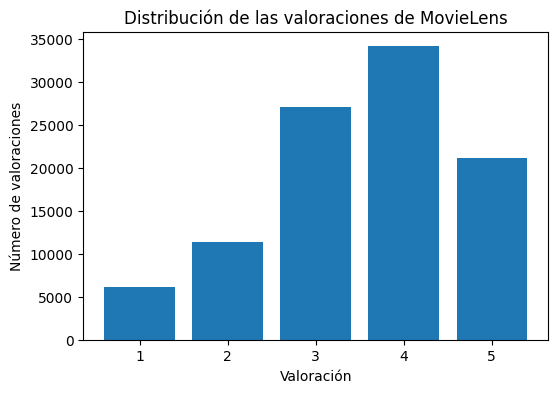

In [7]:
rating_counts = ratings.groupBy("rating").count().orderBy("rating")
rating_counts.show()

rating_counts_pd = rating_counts.toPandas()

plt.figure(figsize=(6, 4))
plt.bar(rating_counts_pd["rating"], rating_counts_pd["count"])
plt.xlabel("Valoración")
plt.ylabel("Número de valoraciones")
plt.title("Distribución de las valoraciones de MovieLens")
plt.show()


## 6. Dividir el conjunto de datos en entrenamiento y prueba

Usamos el 80% de las valoraciones para entrenamiento y el 20% para prueba.


In [8]:
training, test = ratings.randomSplit([0.8, 0.2], seed=42)

training.cache()
test.cache()

print("Valoraciones de entrenamiento:", training.count())
print("Valoraciones de prueba:", test.count())


Valoraciones de entrenamiento: 79901
Valoraciones de prueba: 20099


## 7. Entrenar un modelo de recomendación ALS https://spark.apache.org/docs/latest/api/python/reference/api/pyspark.mllib.recommendation.ALS.html

ALS aprende factores latentes para los usuarios y las películas.  
Estos factores latentes se utilizan para predecir valoraciones desconocidas y recomendar películas.

ALS (Alternating Least Squares) Model Configuration:

*userCol, itemCol, ratingCol*: Specify the DataFrame columns for user IDs, item IDs, and ratings, respectively.

*rank*: The number of latent factors (e.g., 10), influencing the model's complexity and ability to capture patterns.

*maxIter*: The maximum number of iterations for the algorithm to run (e.g., 10), affecting training time and model refinement.

*regParam*: The regularization parameter (e.g., 0.1), used to prevent overfitting by penalizing large factor values.

*coldStartStrategy="drop"*: Handles new users/items not seen during training by dropping their predictions.

*nonnegative=True*: Ensures latent factors are non-negative, which can aid interpretability.

*seed=42*: Sets a random seed for reproducible results


In [9]:
from pyspark.ml.recommendation import ALS
from pyspark.ml.evaluation import RegressionEvaluator

als = ALS(
    userCol="user_id",
    itemCol="item_id",
    ratingCol="rating",
    rank=10,
    maxIter=10,
    regParam=0.1,
    coldStartStrategy="drop",
    nonnegative=True,
    seed=42
)

model = als.fit(training)
print("Modelo ALS entrenado correctamente.")


Modelo ALS entrenado correctamente.


## 8. Evaluar el modelo utilizando RMSE

El RMSE mide el error de predicción entre las valoraciones reales y las valoraciones predichas.  
Un RMSE más bajo indica un mejor rendimiento predictivo.


In [10]:
predictions = model.transform(test)

evaluator = RegressionEvaluator(
    metricName="rmse",
    labelCol="rating",
    predictionCol="prediction"
)

rmse = evaluator.evaluate(predictions)
print(f"Raíz del error cuadrático medio (RMSE) = {rmse:.4f}")

predictions.select("user_id", "item_id", "rating", spark_round("prediction", 2).alias("prediction")).show(10)


Raíz del error cuadrático medio (RMSE) = 0.9187
+-------+-------+------+----------+
|user_id|item_id|rating|prediction|
+-------+-------+------+----------+
|    148|      8|     4|      3.89|
|    148|     56|     5|      3.59|
|    148|     71|     5|       3.4|
|    148|    133|     5|      2.85|
|    148|    169|     5|      4.77|
|    148|    172|     5|      4.49|
|    148|    194|     5|       4.2|
|    148|    222|     4|      3.64|
|    148|    357|     5|      3.54|
|    148|    432|     5|      3.45|
+-------+-------+------+----------+
only showing top 10 rows


## 9. Generar recomendaciones Top-K

Ahora generamos las 10 mejores recomendaciones de películas para cada usuario.


In [11]:
user_recs = model.recommendForAllUsers(10)
user_recs.printSchema()
user_recs.show(5, truncate=False)


root
 |-- user_id: integer (nullable = false)
 |-- recommendations: array (nullable = true)
 |    |-- element: struct (containsNull = true)
 |    |    |-- item_id: integer (nullable = true)
 |    |    |-- rating: float (nullable = true)

+-------+-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|user_id|recommendations                                                                                                                                                                          |
+-------+-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|1      |[{1449, 5.170429}, {169, 5.042872}, {408, 4.972856}, {119, 4.8589892}, {50, 4.832644}, {919, 4.7899537}, {114, 4.727826}, {850, 4.709304}, {1643, 4.67523}, {1149, 4.

Las recomendaciones se almacenan como un array.  
Para leerlas más fácilmente, usamos `explode` y unimos los títulos de las películas.


In [12]:
user_recs_exploded = (
    user_recs
    .select("user_id", explode("recommendations").alias("rec"))
    .select(
        "user_id",
        col("rec.item_id").alias("item_id"),
        spark_round(col("rec.rating"), 2).alias("predicted_rating")
    )
)

user_recs_with_titles = (
    user_recs_exploded
    .join(items, on="item_id", how="left")
    .select("user_id", "item_id", "movie", "predicted_rating")
    .orderBy("user_id", desc("predicted_rating"))
)

user_recs_with_titles.show(20, truncate=False)


+-------+-------+------------------------------------------------------+----------------+
|user_id|item_id|movie                                                 |predicted_rating|
+-------+-------+------------------------------------------------------+----------------+
|1      |1449   |Pather Panchali (1955)                                |5.17            |
|1      |169    |Wrong Trousers, The (1993)                            |5.04            |
|1      |408    |Close Shave, A (1995)                                 |4.97            |
|1      |119    |Maya Lin: A Strong Clear Vision (1994)                |4.86            |
|1      |50     |Star Wars (1977)                                      |4.83            |
|1      |919    |City of Lost Children, The (1995)                     |4.79            |
|1      |114    |Wallace & Gromit: The Best of Aardman Animation (1996)|4.73            |
|1      |850    |Perfect Candidate, A (1996)                           |4.71            |
|1      |1

## 10. Recomendaciones para usuarios seleccionados

Podemos generar recomendaciones solo para usuarios específicos.


In [13]:
selected_users = spark.createDataFrame([(1,), (50,), (196,)], ["user_id"])

selected_user_recs = model.recommendForUserSubset(selected_users, 5)

selected_user_recs_exploded = (
    selected_user_recs
    .select("user_id", explode("recommendations").alias("rec"))
    .select(
        "user_id",
        col("rec.item_id").alias("item_id"),
        spark_round(col("rec.rating"), 2).alias("predicted_rating")
    )
    .join(items, on="item_id", how="left")
    .select("user_id", "movie", "predicted_rating")
    .orderBy("user_id", desc("predicted_rating"))
)

selected_user_recs_exploded.show(30, truncate=False)


+-------+-------------------------------------------------------+----------------+
|user_id|movie                                                  |predicted_rating|
+-------+-------------------------------------------------------+----------------+
|1      |Pather Panchali (1955)                                 |5.17            |
|1      |Wrong Trousers, The (1993)                             |5.04            |
|1      |Close Shave, A (1995)                                  |4.97            |
|1      |Maya Lin: A Strong Clear Vision (1994)                 |4.86            |
|1      |Star Wars (1977)                                       |4.83            |
|50     |Duoluo tianshi (1995)                                  |5.46            |
|50     |Kicking and Screaming (1995)                           |5.36            |
|50     |Brother Minister: The Assassination of Malcolm X (1994)|5.26            |
|50     |Burnt By the Sun (1994)                                |5.15            |
|50 

## 11. Recomendar usuarios para películas seleccionadas

También podemos preguntar qué usuarios tienen más probabilidad de que les gusten películas específicas.


In [14]:
selected_movies = spark.createDataFrame([(50,), (100,), (181,)], ["item_id"])

movie_recs = model.recommendForItemSubset(selected_movies, 5)

movie_recs_exploded = (
    movie_recs
    .select("item_id", explode("recommendations").alias("rec"))
    .select(
        "item_id",
        col("rec.user_id").alias("user_id"),
        spark_round(col("rec.rating"), 2).alias("predicted_rating")
    )
    .join(items, on="item_id", how="left")
    .select("movie", "user_id", "predicted_rating")
    .orderBy("movie", desc("predicted_rating"))
)

movie_recs_exploded.show(30, truncate=False)


+-------------------------+-------+----------------+
|movie                    |user_id|predicted_rating|
+-------------------------+-------+----------------+
|Fargo (1996)             |688    |5.14            |
|Fargo (1996)             |296    |5.04            |
|Fargo (1996)             |157    |5.0             |
|Fargo (1996)             |592    |4.99            |
|Fargo (1996)             |808    |4.95            |
|Return of the Jedi (1983)|849    |5.15            |
|Return of the Jedi (1983)|810    |5.12            |
|Return of the Jedi (1983)|357    |5.06            |
|Return of the Jedi (1983)|688    |5.05            |
|Return of the Jedi (1983)|850    |5.02            |
|Star Wars (1977)         |688    |5.51            |
|Star Wars (1977)         |810    |5.33            |
|Star Wars (1977)         |640    |5.23            |
|Star Wars (1977)         |357    |5.22            |
|Star Wars (1977)         |849    |5.2             |
+-------------------------+-------+-----------

## 12. Comparación simple con películas populares

Un modelo de recomendación no debería recomendar únicamente películas populares de forma global.  
Sin embargo, es útil comparar las recomendaciones de ALS con las películas más valoradas.


In [15]:
popular_movies = (
    ratings
    .groupBy("item_id")
    .agg(
        count("*").alias("num_ratings"),
        spark_round(avg("rating"), 2).alias("avg_rating")
    )
    .join(items, on="item_id", how="left")
    .filter(col("num_ratings") >= 50)
    .orderBy(desc("avg_rating"), desc("num_ratings"))
)

popular_movies.select("movie", "num_ratings", "avg_rating").show(20, truncate=False)


+------------------------------------------------------+-----------+----------+
|movie                                                 |num_ratings|avg_rating|
+------------------------------------------------------+-----------+----------+
|Close Shave, A (1995)                                 |112        |4.49      |
|Schindler's List (1993)                               |298        |4.47      |
|Wrong Trousers, The (1993)                            |118        |4.47      |
|Casablanca (1942)                                     |243        |4.46      |
|Shawshank Redemption, The (1994)                      |283        |4.45      |
|Wallace & Gromit: The Best of Aardman Animation (1996)|67         |4.45      |
|Usual Suspects, The (1995)                            |267        |4.39      |
|Rear Window (1954)                                    |209        |4.39      |
|Star Wars (1977)                                      |583        |4.36      |
|12 Angry Men (1957)                    

# Tarea para el estudiante

Al final de este laboratorio, completa la siguiente tarea de forma individual o en parejas.

## Objetivo

Mejorar y analizar el modelo de recomendación ALS utilizando el conjunto de datos MovieLens 100K.

## Pasos requeridos

1. Prueba al menos **tres configuraciones diferentes de ALS** modificando:
   - `rank`
   - `maxIter`
   - `regParam`

2. Para cada configuración:
   - Entrena el modelo ALS utilizando el conjunto de entrenamiento.
   - Evalúalo sobre el conjunto de prueba.
   - Informa del RMSE obtenido.

3. Crea una tabla con los resultados, por ejemplo:

| Experimento | rank | maxIter | regParam | RMSE |
|---|---:|---:|---:|---:|
| 1 | 10 | 10 | 0.1 | ... |
| 2 | ... | ... | ... | ... |
| 3 | ... | ... | ... | ... |

4. Selecciona el mejor modelo de acuerdo con el RMSE más bajo.

5. Utilizando el mejor modelo:
   - Genera las **5 mejores recomendaciones de películas** para tres usuarios diferentes.
   - Muestra los títulos de las películas y las valoraciones predichas.

6. Crea una figura que muestre el RMSE obtenido para las diferentes configuraciones.

7. Compara las mejores recomendaciones de ALS con las películas más populares del conjunto de datos.  
Responde a esta pregunta:  

**¿ALS recomienda solo películas populares o personaliza las recomendaciones para cada usuario?**

In [16]:
# your code
als = ALS(
    userCol="user_id",
    itemCol="item_id",
    ratingCol="rating",
    rank=5,
    maxIter=5,
    regParam=0.2,
    coldStartStrategy="drop",
    nonnegative=True,
    seed=42
)

model = als.fit(training)
print("Modelo ALS entrenado correctamente.")

predictions = model.transform(test)

evaluator = RegressionEvaluator(
    metricName="rmse",
    labelCol="rating",
    predictionCol="prediction"
)

rmse = evaluator.evaluate(predictions)


predictions.select("user_id", "item_id", "rating", spark_round("prediction", 2).alias("prediction")).show(10)

print(f"Raíz del error cuadrático medio (RMSE) = {rmse:.4f}")


Modelo ALS entrenado correctamente.
Raíz del error cuadrático medio (RMSE) = 0.9477
+-------+-------+------+----------+
|user_id|item_id|rating|prediction|
+-------+-------+------+----------+
|    148|      8|     4|      3.77|
|    148|     56|     5|      3.88|
|    148|     71|     5|       3.3|
|    148|    133|     5|       3.5|
|    148|    169|     5|      4.28|
|    148|    172|     5|      3.92|
|    148|    194|     5|      3.78|
|    148|    222|     4|      3.26|
|    148|    357|     5|      4.03|
|    148|    432|     5|      3.56|
+-------+-------+------+----------+
only showing top 10 rows


In [17]:
# your code
als = ALS(
    userCol="user_id",
    itemCol="item_id",
    ratingCol="rating",
    rank=6,
    maxIter=6,
    regParam=0.3,
    coldStartStrategy="drop",
    nonnegative=True,
    seed=42
)

model = als.fit(training)
print("Modelo ALS entrenado correctamente.")

predictions = model.transform(test)

evaluator = RegressionEvaluator(
    metricName="rmse",
    labelCol="rating",
    predictionCol="prediction"
)

rmse = evaluator.evaluate(predictions)


predictions.select("user_id", "item_id", "rating", spark_round("prediction", 2).alias("prediction")).show(10)

print(f"Raíz del error cuadrático medio (RMSE) = {rmse:.4f}")

Modelo ALS entrenado correctamente.
+-------+-------+------+----------+
|user_id|item_id|rating|prediction|
+-------+-------+------+----------+
|    148|      8|     4|      3.65|
|    148|     56|     5|      3.75|
|    148|     71|     5|      3.37|
|    148|    133|     5|      3.49|
|    148|    169|     5|      4.14|
|    148|    172|     5|      3.81|
|    148|    194|     5|      3.68|
|    148|    222|     4|      3.28|
|    148|    357|     5|      3.95|
|    148|    432|     5|      3.43|
+-------+-------+------+----------+
only showing top 10 rows
Raíz del error cuadrático medio (RMSE) = 0.9853


In [18]:
# your code
als = ALS(
    userCol="user_id",
    itemCol="item_id",
    ratingCol="rating",
    rank=10,
    maxIter=10,
    regParam=0.1,
    coldStartStrategy="drop",
    nonnegative=True,
    seed=42
)

model = als.fit(training)
print("Modelo ALS entrenado correctamente.")

predictions = model.transform(test)

evaluator = RegressionEvaluator(
    metricName="rmse",
    labelCol="rating",
    predictionCol="prediction"
)

rmse = evaluator.evaluate(predictions)


predictions.select("user_id", "item_id", "rating", spark_round("prediction", 2).alias("prediction")).show(10)

print(f"Raíz del error cuadrático medio (RMSE) = {rmse:.4f}")

Modelo ALS entrenado correctamente.
+-------+-------+------+----------+
|user_id|item_id|rating|prediction|
+-------+-------+------+----------+
|    148|      8|     4|      3.89|
|    148|     56|     5|      3.59|
|    148|     71|     5|       3.4|
|    148|    133|     5|      2.85|
|    148|    169|     5|      4.77|
|    148|    172|     5|      4.49|
|    148|    194|     5|       4.2|
|    148|    222|     4|      3.64|
|    148|    357|     5|      3.54|
|    148|    432|     5|      3.45|
+-------+-------+------+----------+
only showing top 10 rows
Raíz del error cuadrático medio (RMSE) = 0.9187


In [23]:


als_results = [
    {"Experimento": 1, "rank": 5, "maxIter": 5, "regParam": 0.2, "RMSE": 0.9477},
    {"Experimento": 2, "rank": 6, "maxIter": 6, "regParam": 0.3, "RMSE": 0.9853},
    {"Experimento": 3, "rank": 10, "maxIter": 10, "regParam": 0.1, "RMSE": 0.9187}
]

results_df = pd.DataFrame(als_results)
display(results_df)
print("Mejor modelo: experimento 3")


,Experimento,rank,maxIter,regParam,RMSE
0,1,5,5,0.2,0.9477
1,2,6,6,0.3,0.9853
2,3,10,10,0.1,0.9187


Mejor modelo: experimento 3


In [22]:
user_recs = model.recommendForAllUsers(10)
user_recs.printSchema()
user_recs.show(5, truncate=False)

selected_users = spark.createDataFrame([(1,), (7,), (33,)], ["user_id"])

selected_user_recs = model.recommendForUserSubset(selected_users, 5)

selected_user_recs_exploded = (
    selected_user_recs
    .select("user_id", explode("recommendations").alias("rec"))
    .select(
        "user_id",
        col("rec.item_id").alias("item_id"),
        spark_round(col("rec.rating"), 2).alias("predicted_rating")
    )
    .join(items, on="item_id", how="left")
    .select("user_id", "movie", "predicted_rating")
    .orderBy("user_id", desc("predicted_rating"))
)

selected_user_recs_exploded.show(30, truncate=False)


root
 |-- user_id: integer (nullable = false)
 |-- recommendations: array (nullable = true)
 |    |-- element: struct (containsNull = true)
 |    |    |-- item_id: integer (nullable = true)
 |    |    |-- rating: float (nullable = true)

+-------+-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|user_id|recommendations                                                                                                                                                                          |
+-------+-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|1      |[{1449, 5.170429}, {169, 5.042872}, {408, 4.972856}, {119, 4.8589892}, {50, 4.832644}, {919, 4.7899537}, {114, 4.727826}, {850, 4.709304}, {1643, 4.67523}, {1149, 4.

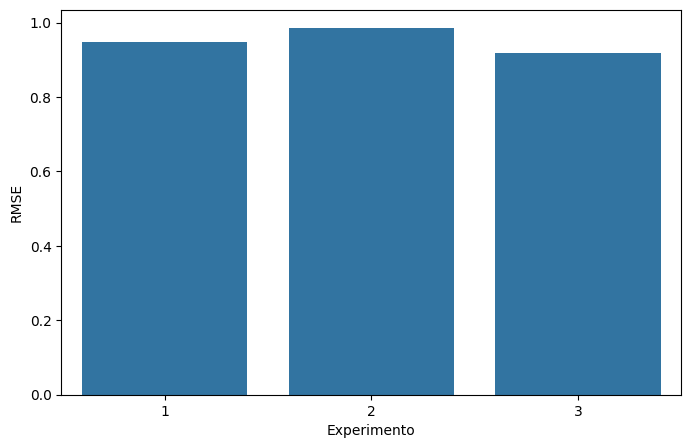

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.barplot(x='Experimento', y='RMSE', data=results_df)
plt.xlabel('Experimento')
plt.ylabel('RMSE')
plt.show()

In [30]:
popular_movies = (
    ratings
    .groupBy("item_id")
    .agg(
        count("*").alias("num_ratings"),
        spark_round(avg("rating"), 2).alias("avg_rating")
    )
    .join(items, on="item_id", how="left")
    .filter(col("num_ratings") >= 50)
    .orderBy(desc("avg_rating"), desc("num_ratings"))
)

popular_movies.select("movie", "num_ratings", "avg_rating").show(20, truncate=False)

+------------------------------------------------------+-----------+----------+
|movie                                                 |num_ratings|avg_rating|
+------------------------------------------------------+-----------+----------+
|Close Shave, A (1995)                                 |112        |4.49      |
|Schindler's List (1993)                               |298        |4.47      |
|Wrong Trousers, The (1993)                            |118        |4.47      |
|Casablanca (1942)                                     |243        |4.46      |
|Shawshank Redemption, The (1994)                      |283        |4.45      |
|Wallace & Gromit: The Best of Aardman Animation (1996)|67         |4.45      |
|Usual Suspects, The (1995)                            |267        |4.39      |
|Rear Window (1954)                                    |209        |4.39      |
|Star Wars (1977)                                      |583        |4.36      |
|12 Angry Men (1957)                    

El algoritmo ALS sí personaliza las recomendaciones para cada usuario comparando las dos tablas se puede ver la diferencia.

### Las películas más recomendadas para los usuarios seleccionados

Vamos a identificar las películas que aparecen con mayor frecuencia en las recomendaciones de los usuarios seleccionados. Esto nos ayudará a entender qué películas son 'repetidas' en sus listas.

Acabamos de generar el gráfico de barras que muestra las películas más recomendadas para los usuarios seleccionados, como se solicitó en el apartado "Las películas más recomendadas para los usuarios seleccionados".

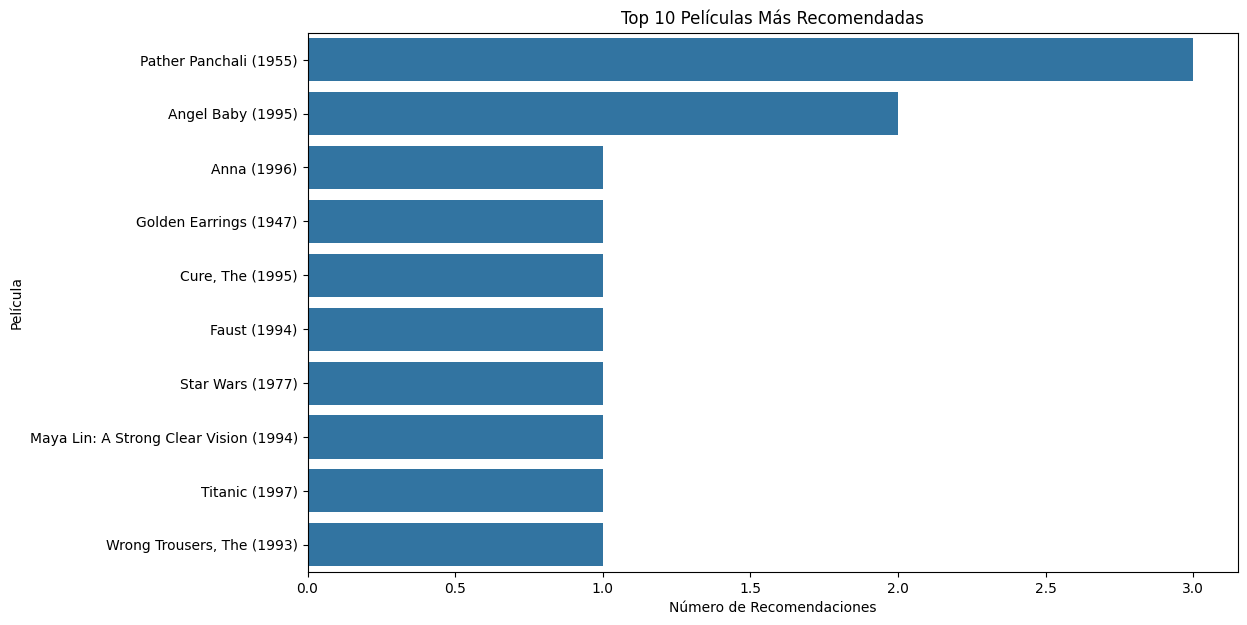

In [33]:

recommended_movie_counts = (
    selected_user_recs_exploded
    .groupBy("movie")
    .agg(count("movie").alias("recommendation_count"))
    .orderBy(desc("recommendation_count"))
)


recommended_movie_counts_pd = recommended_movie_counts.toPandas()

plt.figure(figsize=(12, 7))
sns.barplot(x='recommendation_count', y='movie', data=recommended_movie_counts_pd.head(10))
plt.title('Top 10 Películas Más Recomendadas')
plt.xlabel('Número de Recomendaciones')
plt.ylabel('Película')
plt.show()

### Cierre de la sesión

In [34]:
spark.stop()